# Systemy AI – Laboratorium 7 – Mark Ponomarev – 437962
## Zadanie: klasyfikator softmax w PyTorch – pingwiny

Napisz samodzielnie w PyTorch klasyfikator softmax, który rozpoznaje **gatunek pingwina** (Adelie, Chinstrap, Gentoo) na podstawie **dwóch** cech: długości i wysokości dzioba. Znasz te dane z Lab 4 – tym razem nie używasz gotowego `fit`, tylko sam(a) piszesz pętlę uczenia. Wzoruj się na notatniku `SystemyAI_Lab7_wzor.ipynb`.

Dwie cechy wybraliśmy celowo: wynik da się narysować na płaszczyźnie, a zadanie nie jest trywialne (Adelie i Chinstrap częściowo na siebie nachodzą).

**Zasady** (jak poprzednio): nazwy zmiennych z treści są obowiązkowe; komórek `# TEST` nie zmieniaj; przed oddaniem *Uruchom ponownie i uruchom wszystko*.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)                 # powtarzalność losowania wag w PyTorch
rng = np.random.default_rng(42)       # powtarzalność losowania danych w NumPy
print("PyTorch", torch.__version__)

PyTorch 2.14.1+cpu


---
## 1. Dane → tensory
1. Wczytaj `sns.load_dataset("penguins")`, zostaw wiersze bez braków w `bill_length_mm`, `bill_depth_mm`, `species`.
2. Zamień gatunki na liczby: `gatunki = ["Adelie", "Chinstrap", "Gentoo"]` → 0, 1, 2.
3. Podział **trzyczęściowy** (dwa razy `train_test_split`, `stratify`, `random_state=42`): najpierw 20% na test, potem z reszty 25% na walidację. Wyjdzie 204 / 69 / 69.
4. `StandardScaler` dopasowany **tylko** na train; przekształć wszystkie trzy zbiory.
5. Tensory: `X_tr`, `X_va`, `X_te` (`float32`) oraz `y_tr`, `y_va`, `y_te` (`long`).

Zbiór walidacyjny posłuży do krzywych uczenia i wyboru learning rate, testowy – raz, na końcu.

In [2]:
# Twoje rozwiązanie
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Wczytanie danych i usunięcie braków w wybranych kolumnach
df = sns.load_dataset("penguins").dropna(subset=["bill_length_mm", "bill_depth_mm", "species"])

# 2. Wybór cech oraz mapowanie gatunków na liczby 0, 1, 2
gatunki = ["Adelie", "Chinstrap", "Gentoo"]
X = df[["bill_length_mm", "bill_depth_mm"]].values
y = df["species"].map({g: i for i, g in enumerate(gatunki)}).values

# 3. Podział trzyczęściowy (najpierw 20% test, potem z reszty 25% walidacja -> 60% / 20% / 20%)
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=42
)

# 4. Standaryzacja dopasowana wyłącznie na zbiorze treningowym
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_val_sc = scaler.transform(X_val)
X_test_sc = scaler.transform(X_test)

# 5. Konwersja na tensory PyTorch o odpowiednich typach (float32 i long)
X_tr = torch.tensor(X_train_sc, dtype=torch.float32)
X_va = torch.tensor(X_val_sc, dtype=torch.float32)
X_te = torch.tensor(X_test_sc, dtype=torch.float32)

y_tr = torch.tensor(y_train, dtype=torch.long)
y_va = torch.tensor(y_val, dtype=torch.long)
y_te = torch.tensor(y_test, dtype=torch.long)

# Weryfikacja wymiarów (powinno wyjść 204 / 69 / 69)
print(f"Rozmiary zbiorów: train={len(X_tr)}, val={len(X_va)}, test={len(X_te)}")


Rozmiary zbiorów: train=204, val=69, test=69


In [3]:
# TEST
assert X_tr.shape == (204, 2) and X_va.shape == (69, 2) and X_te.shape == (69, 2)
assert X_tr.dtype == torch.float32 and y_tr.dtype == torch.long
assert set(y_tr.tolist()) == {0, 1, 2}
assert torch.allclose(X_tr.mean(dim=0), torch.zeros(2), atol=1e-5), "Standaryzacja dopasowana na train"
print("1 OK")

1 OK


---
## 2. Model i strata przed uczeniem
1. `torch.manual_seed(0)`, potem `model = nn.Linear(2, 3)` i `loss_fn = nn.CrossEntropyLoss()`.
2. Policz `loss0` – stratę na zbiorze treningowym **przed** uczeniem (`.item()`).
3. Policz `p0` – prawdopodobieństwa (softmax) dla pierwszych 3 pingwinów treningowych i wypisz je.

In [4]:
# Twoje rozwiązanie
# 1. Inicjalizacja generatora, modelu liniowego (2 cechy -> 3 klasy) oraz funkcji straty
torch.manual_seed(0)
model = nn.Linear(2, 3)
loss_fn = nn.CrossEntropyLoss()

# 2. Obliczenie straty przed uczeniem oraz prawdopodobieństw dla pierwszych 3 przykładów
with torch.no_grad():
    loss0 = loss_fn(model(X_tr), y_tr).item()
    p0 = torch.softmax(model(X_tr[:3]), dim=1)

print(f"Strata przed uczeniem (loss0): {loss0:.4f} (teoretyczne ln(3) ≈ {np.log(3):.4f})")
print("Prawdopodobieństwa (p0) dla pierwszych 3 pingwinów:")
print(p0.numpy().round(4))

Strata przed uczeniem (loss0): 1.5298 (teoretyczne ln(3) ≈ 1.0986)
Prawdopodobieństwa (p0) dla pierwszych 3 pingwinów:
[[0.1938 0.5522 0.2539]
 [0.3298 0.3845 0.2857]
 [0.4144 0.2371 0.3485]]


In [5]:
# TEST
assert 0.8 < loss0 < 2.0
assert torch.allclose(p0.sum(dim=1), torch.ones(3))
print("2 OK")

2 OK


*Twoja odpowiedź:* model, który dla każdego pingwina daje wszystkim trzem gatunkom prawdopodobieństwo 1/3, ma stratę dokładnie ln 3 ≈ 1.10. Dlaczego? Czy twoja `loss0` jest blisko tej wartości?

- Dlatego, że wzór na wieloklasową entropię krzyżową dla pojedynczego przykładu to $L = -ln(p_y)$, gdzie $p_{y}$ to prawdopodobieństwo przypisane przez model prawdziwej klasie. Gdy model jest całkowicie niezdecydowany i każdej z trzech klas przypisuje prawdopodobieństwo $p_y = \frac{1}{3}$, strata wynosi dokładnie $-ln\left(\frac{1}{3}\right)$ = $ln 3 \approx 1.0986$

- Uzyskana wartość `loss0 = 1.5298` znajduje się w tym samym rzędzie wielkości, ale jest nieco wyższa niż $1.10$. Wynika to z losowej inicjalizacji wag warstwy `nn.Linear(2, 3)` (przy `seed=0`), przez co model już na starcie nie rozkłada prawdopodobieństw idealnie po równo (np. w pierwszym przykładzie daje ponad $55\%$ na klasę 1) i przy błędnych trafieniach otrzymuje wyższą karę

---
## 3. Pętla uczenia
Napisz funkcję `train(lr, epochs=100, batch_size=32, X=X_tr, seed=0, X_val=X_va)`, która:
- ustawia `torch.manual_seed(seed)` i tworzy **nowy** `nn.Linear(2, 3)`, `CrossEntropyLoss` i `optim.SGD(..., lr=lr)`,
- uczy model mini-batchami (`DataLoader` z `shuffle=True`) przez `epochs` epok,
- po każdej epoce zapisuje w słowniku `historia` trzy listy: `"train loss"` (na `X`), `"val loss"` i `"val acc"` (na `X_val`); parametry `X` i `X_val` przydadzą się w punkcie 5,
- zwraca `(model, historia)`.

Uruchom ją dla `lr=0.1` (`model_01, hist_01`) i narysuj dwa wykresy: straty train/val oraz accuracy val w funkcji epoki.

val accuracy po 100 epokach: 0.971


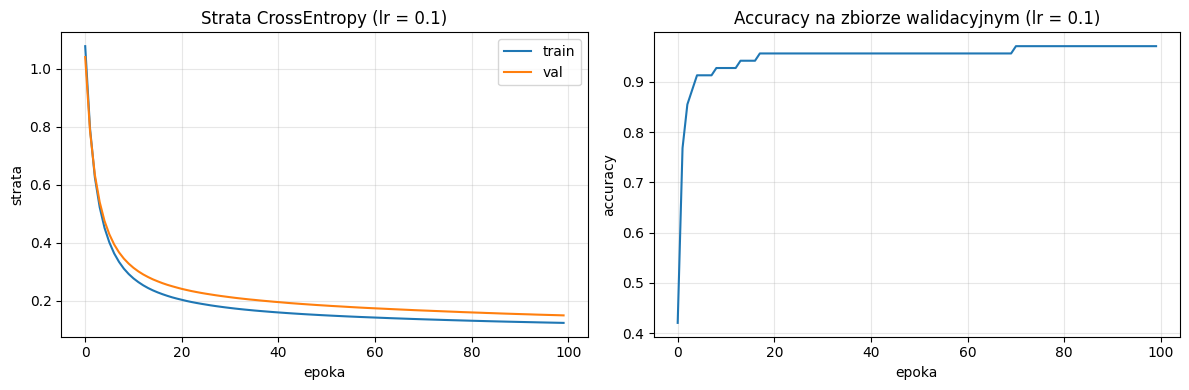

In [6]:
# Twoje rozwiązanie
def train(lr, epochs=100, batch_size=32, X=X_tr, seed=0, X_val=X_va):
  torch.manual_seed(seed)
  model = nn.Linear(2, 3)
  loss_fn = nn.CrossEntropyLoss()
  optimizer = optim.SGD(model.parameters(), lr=lr)
  loader = DataLoader(TensorDataset(X, y_tr), batch_size=batch_size, shuffle=True)

  historia = {"train loss": [], "val loss": [], "val acc": []}

  for epoka in range(epochs):
    for x_batch, y_batch in loader:
      loss = loss_fn(model(x_batch), y_batch)
      optimizer.zero_grad()
      loss.backward()
      optimizer.step()

    with torch.no_grad():
      historia["train loss"].append(loss_fn(model(X), y_tr).item())
      historia["val loss"].append(loss_fn(model(X_val), y_va).item())
      historia["val acc"].append((model(X_val).argmax(dim=1) == y_va).float().mean().item())

  return model, historia

# Uruchomienie dla lr = 0.1
model_01, hist_01 = train(lr=0.1)
print(f"val accuracy po 100 epokach: {hist_01['val acc'][-1]:.3f}")

# Wykresy krzywych uczenia (strata oraz accuracy w funkcji epoki)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(hist_01["train loss"], label="train")
axes[0].plot(hist_01["val loss"], label="val")
axes[0].set_title("Strata CrossEntropy (lr = 0.1)")
axes[0].set_xlabel("epoka")
axes[0].set_ylabel("strata")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(hist_01["val acc"], label="val acc")
axes[1].set_title("Accuracy na zbiorze walidacyjnym (lr = 0.1)")
axes[1].set_xlabel("epoka")
axes[1].set_ylabel("accuracy")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [7]:
# TEST
assert set(hist_01) == {"train loss", "val loss", "val acc"} and len(hist_01["val acc"]) == 100
assert hist_01["train loss"][-1] < hist_01["train loss"][0], "Strata powinna maleć"
assert hist_01["val acc"][-1] > 0.9
print("3 OK")

3 OK


---
## 4. Learning rate
Naucz model dla `lr` ∈ {0.001, 0.01, 0.1, 1.0}. Na jednym wykresie narysuj krzywe **straty treningowej** dla wszystkich czterech wartości, a wyniki końcowe (`val loss`, `val acc` po 100 epokach) zbierz w `pd.DataFrame` o nazwie `wyniki_lr` (indeks: wartości lr).

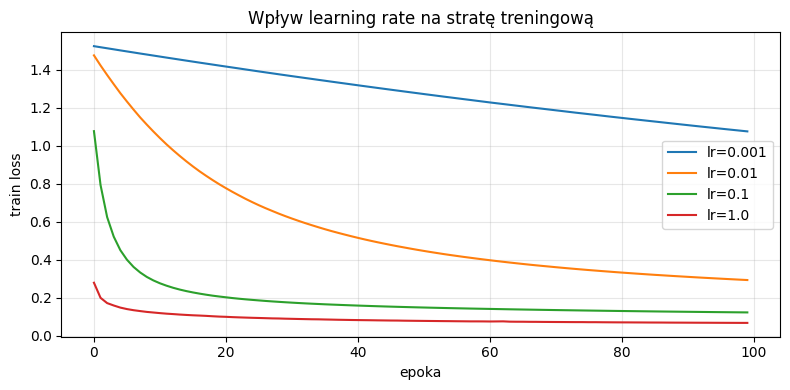



       val loss  val acc
lr                      
0.001    1.0382   0.4203
0.010    0.3294   0.9275
0.100    0.1492   0.9710
1.000    0.0724   0.9710


In [8]:
# Twoje rozwiązanie
import pandas as pd

lrs = [0.001, 0.01, 0.1, 1.0]
wiersze = []

fig, ax = plt.subplots(figsize=(8, 4))

for lr in lrs:
  _, hist = train(lr, epochs=100)
  ax.plot(hist["train loss"], label=f"lr={lr}")
  wiersze.append({
        "val loss": hist["val loss"][-1],
        "val acc": hist["val acc"][-1]
  })

ax.set_title("Wpływ learning rate na stratę treningową")
ax.set_xlabel("epoka")
ax.set_ylabel("train loss")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

wyniki_lr = pd.DataFrame(wiersze, index=pd.Index(lrs, name="lr"))
print("\n")
print(wyniki_lr.round(4))

In [9]:
# TEST
assert list(wyniki_lr.index) == [0.001, 0.01, 0.1, 1.0]
assert wyniki_lr.loc[0.001, "val loss"] > wyniki_lr.loc[0.1, "val loss"]
print("4 OK")

4 OK


*Twoja odpowiedź:* co widać dla lr = 0.001? Który learning rate wybierasz i na podstawie którego zbioru?

- Dla `lr = 0.001` krzywa straty opada bardzo wolno i niemal liniowo, a po 100 epokach strata treningowa wciąż przekracza $1.0$. Kroki aktualizacji wag są zbyt małe, przez co model jest silnie niedouczony i osiąga na walidacji dokładność zaledwie 0.4203 ($42.0\%$)

- Wybieram lr = 1.0 (lub bezpiecznie `lr = 0.1` / `lr = 1.0` - oba dają najwyższą skuteczność `val acc = 0.9710`, przy czym `lr = 1.0` osiąga wyraźnie najniższą stratę `val loss = 0.0724` oraz najszybszą zbieżność). Wyboru dokonuję wyłącznie na podstawie zbioru walidacyjnego (`X_va`, `y_va`), aby zbiór testowy pozostał nietknięty do końcowej oceny modelu


---
## 5. Co daje standaryzacja?
Utwórz `X_tr_raw` i `X_va_raw` – tensory **bez** standaryzacji (surowe milimetry z `X_train`, `X_val`) i naucz model z `lr=0.1`: `train(0.1, X=X_tr_raw, X_val=X_va_raw)`. Porównaj końcową stratę i accuracy z wynikiem z punktu 3. Wynik zapisz w `hist_raw`.

In [10]:
# Twoje rozwiązanie
# 1. Utworzenie tensorów z surowych danych (bez standaryzacji)
X_tr_raw = torch.tensor(X_train, dtype=torch.float32)
X_va_raw = torch.tensor(X_val, dtype=torch.float32)

# 2. Uczenie modelu na surowych danych z lr = 0.1
model_raw, hist_raw = train(0.1, X=X_tr_raw, X_val=X_va_raw)

# 3. Porównanie końcowych wyników po 100 epokach
print("Ze standaryzacją (punkt 3):")
print(f"  train loss: {hist_01['train loss'][-1]:.4f} | val loss: {hist_01['val loss'][-1]:.4f} | val acc: {hist_01['val acc'][-1]:.4f}")

print("\nBez standaryzacji (surowe dane):")
print(f"  train loss: {hist_raw['train loss'][-1]:.4f} | val loss: {hist_raw['val loss'][-1]:.4f} | val acc: {hist_raw['val acc'][-1]:.4f}")

Ze standaryzacją (punkt 3):
  train loss: 0.1233 | val loss: 0.1492 | val acc: 0.9710

Bez standaryzacji (surowe dane):
  train loss: 27.6107 | val loss: 29.0971 | val acc: 0.7971


In [11]:
# TEST
assert hist_raw["val acc"][-1] < hist_01["val acc"][-1]
print("5 OK")

5 OK


*Twoja odpowiedź:* dlaczego bez standaryzacji uczenie idzie tak źle, choć model i dane są te same?

- Uczenie idzie tak źle, ponieważ występuje różna skala cech i ogromne gradienty - bez standaryzacji obie cechy wyrażone są w milimetrach, a ich wartości są znacznie większe od zera i mają różny rozrzut. Ponieważ gradient straty po wagach jest wprost proporcjonalny do wartości cech wejściowych $(\frac{\partial L}{\partial w} \propto x)$, gradienty przyjmują bardzo duże wartości.
Ponadto, współczynnik uczenia lr = 0.1 jest dobrany pod dane o średniej $0$ i odchyleniu $1$. Przy dużych gradientach z surowych milimetrów aktualizacje wag są gwałtowne - model zamiast schodzić w dół funkcji straty, oscyluje i „przeskakuje” dolinę minimum, przez co strata szybuje do `29.0971`, a skuteczność spada do `0.7971`


---
## 6. Ocena końcowa i porównanie ze scikit-learn
1. Wybierz model z punktu 4 (wybór na podstawie walidacji) i zapisz go jako `model_koncowy`. Policz `acc_test` – accuracy na **teście**.
2. Naucz `LogisticRegression()` ze scikit-learn na tych samych wystandaryzowanych danych treningowych i policz jej accuracy na teście: `acc_sk`.
3. Wypisz prawdopodobieństwa (softmax) Twojego modelu dla pierwszych 5 pingwinów testowych, z nazwami gatunków i prawdziwym gatunkiem.
4. Narysuj obszary decyzyjne `model_koncowy` na płaszczyźnie (wystandaryzowane cechy) z punktami treningowymi – możesz skopiować funkcję `granica` z wzoru.

PyTorch      accuracy (test): 0.9565
scikit-learn accuracy (test): 0.9275

Prawdopodobieństwa dla pierwszych 5 pingwinów testowych:
   Adelie  Chinstrap  Gentoo prawdziwy_gatunek
0  0.9689     0.0311  0.0000            Adelie
1  0.9826     0.0173  0.0001            Adelie
2  0.0000     0.0052  0.9948            Gentoo
3  0.0014     0.1100  0.8887            Gentoo
4  0.0873     0.9091  0.0035         Chinstrap 



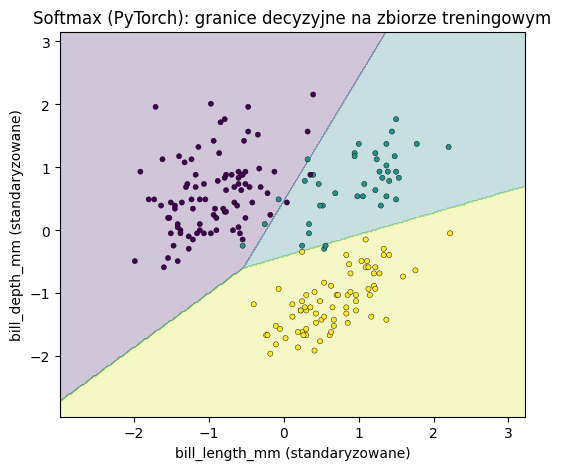

In [12]:
from sklearn.linear_model import LogisticRegression

# 1. Wybór najlepszego modelu na podstawie walidacji (lr = 1.0 z punktu 4) i ocena na zbiorze testowym
model_koncowy, _ = train(lr=1.0, epochs=100)

with torch.no_grad():
    acc_test = (model_koncowy(X_te).argmax(dim=1) == y_te).float().mean().item()

# 2. Porównanie z LogisticRegression ze scikit-learn na tych samych wystandaryzowanych danych
sk = LogisticRegression().fit(X_train_sc, y_train)
acc_sk = sk.score(X_test_sc, y_test)

print(f"PyTorch      accuracy (test): {acc_test:.4f}")
print(f"scikit-learn accuracy (test): {acc_sk:.4f}\n")

# 3. Prawdopodobieństwa (softmax) dla pierwszych 5 pingwinów testowych
with torch.no_grad():
    p_test = torch.softmax(model_koncowy(X_te[:5]), dim=1)

df_p5 = pd.DataFrame(p_test.numpy(), columns=gatunki).round(4)
df_p5["prawdziwy_gatunek"] = [gatunki[i] for i in y_te[:5]]
print("Prawdopodobieństwa dla pierwszych 5 pingwinów testowych:")
print(df_p5, "\n")

# 4. Rysowanie obszarów decyzyjnych model_koncowy na wystandaryzowanych danych treningowych
def granica(model, X, y, tytul, softmax=False):
    """Rysuje obszary decyzyjne modelu na płaszczyźnie i punkty danych."""
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, 300),
                         np.linspace(X[:, 1].min() - 1, X[:, 1].max() + 1, 300))
    siatka = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32)
    with torch.no_grad():
        out = model(siatka)
        Z = out.argmax(dim=1) if softmax else (out > 0).squeeze(1)
    fig, ax = plt.subplots(figsize=(6, 5))
    ax.contourf(xx, yy, Z.reshape(xx.shape).numpy(), alpha=0.25, cmap="viridis")
    ax.scatter(X[:, 0], X[:, 1], c=y, s=14, cmap="viridis", edgecolors="k", linewidths=0.3)
    ax.set_title(tytul)
    ax.set_xlabel("bill_length_mm (standaryzowane)")
    ax.set_ylabel("bill_depth_mm (standaryzowane)")
    plt.show()

granica(model_koncowy, X_train_sc, y_train, "Softmax (PyTorch): granice decyzyjne na zbiorze treningowym", softmax=True)


In [13]:
# TEST
assert 0.85 < acc_test <= 1.0
assert abs(acc_test - acc_sk) <= 0.06, "Ten sam model - wyniki powinny być bardzo podobne"
assert torch.allclose(p_test.sum(dim=1), torch.ones(5))
print("6 OK")

6 OK


*Twoja odpowiedź:*
1. Jak wypada Twój model w porównaniu ze scikit-learn? Czy to zaskakujące?
2. Gdzie leżą błędy modelu na wykresie obszarów decyzyjnych? Czy model liniowy mógłby tu zrobić coś lepiej?
3. Wymień kroki pętli uczenia i powiedz jednym zdaniem, co robi każdy z nich.
---
1. Model w PyTorch osiąga bardzo zbliżony, a nawet minimalnie wyższy wynik na zbiorze testowym (`0.9565` wobec `0.9275` dla `scikit-learn`, co przy 69 próbkach odpowiada różnicy zaledwie dwóch pingwinów). Nie jest to zaskakujące, ponieważ oba modele uczą dokładnie tej samej funkcji liniowej z entropią krzyżową jako funkcją straty. Niewielka różnica wynika z tego, że `scikit-learn` domyślnie stosuje regularyzację L2 i inny algorytm optymalizacji, podczas gdy nasz model używa czystego SGD bez regularyzacji

2. Pojedyncze błędnie sklasyfikowane punkty leżą niemal wyłącznie na granicy między gatunkami Adelie (fioletowy) i Chinstrap (morski), gdzie obie chmury punktów częściowo na siebie nachodzą. Model liniowy nie może zrobić tu nic więcej, ponieważ jego granice decyzyjne są z definicji liniami prostymi, a przy dwóch wybranych cechach klasy te nie są w pełni liniowo separowalne

3. Poniżej kroki pętli uczenia:
- Forward (`model(x_batch)`): Przepuszcza porcję danych przez warstwę liniową, aby obliczyć surowe przewidywania (logity) dla każdej klasy

- Loss (`loss = loss_fn(model(x_batch), y_batch)`): Mierzy za pomocą entropii krzyżowej, jak bardzo przewidywania modelu różnią się od prawdziwych etykiet

- Zero grad (`optimizer.zero_grad()`): Zeruje gradienty z poprzedniej iteracji, aby się nie sumowały w kolejnych krokach

- Backward (`loss.backward()`): Wykorzystuje mechanizm autograd do automatycznego obliczenia gradientu funkcji straty względem wszystkich wag i biasów modelu

- Step (`optimizer.step()`): Aktualizuje wagi i biasy modelu, wykonując krok o wielkości `lr` w kierunku przeciwnym do gradientu, aby zmniejszyć stratę

---
## 7. Dla chętnych
1. **Batch size:** naucz model z `lr=0.1` dla `batch_size` ∈ {8, 32, 204} (204 = cały zbiór naraz). Porównaj krzywe straty. Który wariant robi najwięcej kroków w epoce? Który uczy się najszybciej w przeliczeniu na epoki?
2. **Adam:** zamień `optim.SGD` na `optim.Adam` (lr = 0.01) i porównaj krzywe z SGD.
3. **Więcej cech:** dodaj `flipper_length_mm` i `body_mass_g` (`nn.Linear(4, 3)`). Ile zyskuje accuracy?

batch_size =   8 -> kroki w epoce: 26 | końcowa train loss: 0.0853 | val acc: 0.9565
batch_size =  32 -> kroki w epoce:  7 | końcowa train loss: 0.1233 | val acc: 0.9710
batch_size = 204 -> kroki w epoce:  1 | końcowa train loss: 0.2415 | val acc: 0.9420


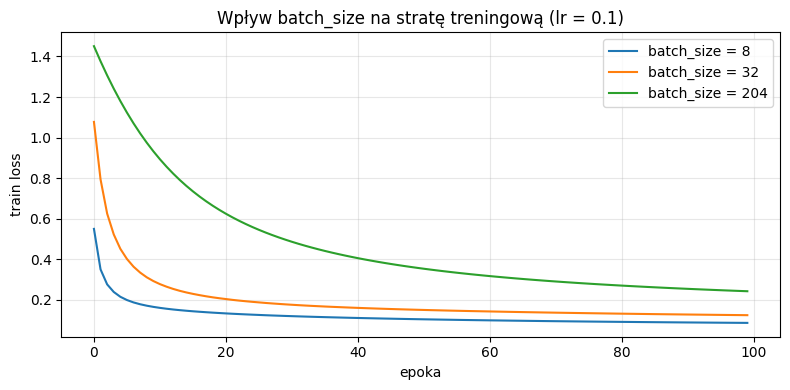

In [14]:
# 7.1
batch_sizes = [8, 32, 204]

fig, ax = plt.subplots(figsize=(8, 4))

for bs in batch_sizes:
    _, hist_bs = train(lr=0.1, epochs=100, batch_size=bs)
    ax.plot(hist_bs["train loss"], label=f"batch_size = {bs}")
    print(f"batch_size = {bs:3d} -> kroki w epoce: {int(np.ceil(len(X_tr) / bs)):2d} | końcowa train loss: {hist_bs['train loss'][-1]:.4f} | val acc: {hist_bs['val acc'][-1]:.4f}")

ax.set_title("Wpływ batch_size na stratę treningową (lr = 0.1)")
ax.set_xlabel("epoka")
ax.set_ylabel("train loss")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

- Który wariant robi najwięcej kroków w epoce? Najwięcej kroków robi `batch_size = 8`. Zbiór treningowy liczy $204$ przykłady, więc przy podziale po $8$ próbek model wykonuje $\lceil 204 / 8 \rceil = \mathbf{26}$ kroków aktualizacji wag w jednej epoce (`dla batch_size = 32` jest to $\lceil 204 / 32 \rceil = \mathbf{7}$ kroków, a dla batch_size = 204 zaledwie $1$ krok na epokę)

- Który uczy się najszybciej w przeliczeniu na epoki? Najszybciej w przeliczeniu na epoki uczy się `batch_size = 8` (jego krzywa straty spada najbardziej stromo już w pierwszych kilku epokach). Wynika to właśnie z faktu, że w trakcie pojedynczej epoki optymalizator aktualizuje wagi aż $26$ razy zamiast $7$ czy $1$ raz

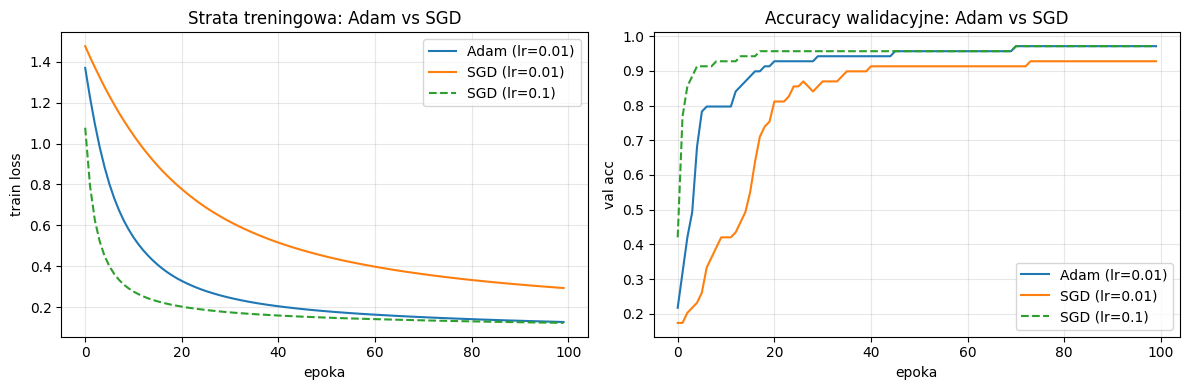

Adam (lr=0.01) -> val loss: 0.1532 | val acc: 0.9710
SGD  (lr=0.01) -> val loss: 0.3294 | val acc: 0.9275
SGD  (lr=0.10) -> val loss: 0.1492 | val acc: 0.9710


In [15]:
# 7.2
def train_adam(lr=0.01, epochs=100, batch_size=32, X=X_tr, seed=0, X_val=X_va):
    torch.manual_seed(seed)
    model = nn.Linear(2, 3)
    loss_fn = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    loader = DataLoader(TensorDataset(X, y_tr), batch_size=batch_size, shuffle=True)

    historia = {"train loss": [], "val loss": [], "val acc": []}

    for epoka in range(epochs):
        for x_batch, y_batch in loader:
            loss = loss_fn(model(x_batch), y_batch)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        with torch.no_grad():
            historia["train loss"].append(loss_fn(model(X), y_tr).item())
            historia["val loss"].append(loss_fn(model(X_val), y_va).item())
            historia["val acc"].append((model(X_val).argmax(dim=1) == y_va).float().mean().item())

    return model, historia

# Uruchomienie dla Adam (lr=0.01) oraz SGD (lr=0.01 i lr=0.1 dla porównania)
_, hist_adam = train_adam(lr=0.01, epochs=100)
_, hist_sgd_001 = train(lr=0.01, epochs=100)

# Wykres porównawczy krzywych straty
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(hist_adam["train loss"], label="Adam (lr=0.01)")
axes[0].plot(hist_sgd_001["train loss"], label="SGD (lr=0.01)")
axes[0].plot(hist_01["train loss"], label="SGD (lr=0.1)", linestyle="--")
axes[0].set_title("Strata treningowa: Adam vs SGD")
axes[0].set_xlabel("epoka")
axes[0].set_ylabel("train loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(hist_adam["val acc"], label="Adam (lr=0.01)")
axes[1].plot(hist_sgd_001["val acc"], label="SGD (lr=0.01)")
axes[1].plot(hist_01["val acc"], label="SGD (lr=0.1)", linestyle="--")
axes[1].set_title("Accuracy walidacyjne: Adam vs SGD")
axes[1].set_xlabel("epoka")
axes[1].set_ylabel("val acc")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Adam (lr=0.01) -> val loss: {hist_adam['val loss'][-1]:.4f} | val acc: {hist_adam['val acc'][-1]:.4f}")
print(f"SGD  (lr=0.01) -> val loss: {hist_sgd_001['val loss'][-1]:.4f} | val acc: {hist_sgd_001['val acc'][-1]:.4f}")
print(f"SGD  (lr=0.10) -> val loss: {hist_01['val loss'][-1]:.4f} | val acc: {hist_01['val acc'][-1]:.4f}")

Porównując krzywe z SGD możemy dojść do wniosku, że:
- Jest szybsza zbieżność przy tym samym `lr = 0.01`: `Adam` zbiega znacznie szybciej niż czysty SGD z tym samym współczynnikiem uczenia `0.01`, osiągając niską stratę już w pierwszych 20-30 epokach. Dzieje się tak, ponieważ `Adam` dostosowuje wielkość kroku osobno dla każdej wagi na podstawie średnich kroczących gradientów i ich kwadratów (momentum + adaptacyjny krok).
- Porównanie z dobrze dobranym `SGD` (`lr = 0.1`): Dla prostego modelu liniowego o 2 cechach `Adam (lr=0.01)` i `SGD (lr=0.1)` osiągają praktycznie identyczną skuteczność końcową (około `0.9710` na walidacji), jednak `Adam` jest znacznie mniej wrażliwy na ręczne strojenie `learning rate` i stabilniej radzi sobie w bardziej złożonych sieciach


In [16]:
# 7.3
# 1. Wczytanie danych z 4 cechami numerycznymi i usunięcie wierszy z brakami
cechy_4 = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
df4 = sns.load_dataset("penguins").dropna(subset=cechy_4 + ["species"])

X4 = df4[cechy_4].values
y4 = df4["species"].map({g: i for i, g in enumerate(gatunki)}).values

# 2. Identyczny podział warstwowy 60% / 20% / 20%
X4_temp, X4_test, y4_temp, y4_test = train_test_split(
    X4, y4, test_size=0.2, stratify=y4, random_state=42
)
X4_train, X4_val, y4_train, y4_val = train_test_split(
    X4_temp, y4_temp, test_size=0.25, stratify=y4_temp, random_state=42
)

# 3. Standaryzacja dopasowana wyłącznie na zbiorze treningowym
scaler4 = StandardScaler()
X4_tr = torch.tensor(scaler4.fit_transform(X4_train), dtype=torch.float32)
X4_va = torch.tensor(scaler4.transform(X4_val), dtype=torch.float32)
X4_te = torch.tensor(scaler4.transform(X4_test), dtype=torch.float32)

y4_tr = torch.tensor(y4_train, dtype=torch.long)
y4_va = torch.tensor(y4_val, dtype=torch.long)
y4_te = torch.tensor(y4_test, dtype=torch.long)

# 4. Uczenie modelu nn.Linear(4, 3) z lr = 1.0 (jak model_koncowy)
torch.manual_seed(0)
model_4 = nn.Linear(4, 3)
loss_fn = nn.CrossEntropyLoss()
optimizer = optim.SGD(model_4.parameters(), lr=1.0)
loader4 = DataLoader(TensorDataset(X4_tr, y4_tr), batch_size=32, shuffle=True)

for epoka in range(100):
    for xb_, yb_ in loader4:
        loss = loss_fn(model_4(xb_), yb_)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

# 5. Ocena końcowa na zbiorze walidacyjnym i testowym
with torch.no_grad():
    acc4_val = (model_4(X4_va).argmax(dim=1) == y4_va).float().mean().item()
    acc4_test = (model_4(X4_te).argmax(dim=1) == y4_te).float().mean().item()

print(f"2 cechy (model_koncowy) -> test accuracy: {acc_test:.4f}")
print(f"4 cechy (model_4)       -> val accuracy:  {acc4_val:.4f} | test accuracy: {acc4_test:.4f}")
print(f"Zysk na zbiorze testowym: +{(acc4_test - acc_test) * 100:.2f} pkt proc.")

2 cechy (model_koncowy) -> test accuracy: 0.9565
4 cechy (model_4)       -> val accuracy:  0.9855 | test accuracy: 1.0000
Zysk na zbiorze testowym: +4.35 pkt proc.


Ile zyskuje accuracy?
- Wzrost dokładności o +4.35 punktu procentowego (do 100%):

Po dodaniu długości płetwy (`flipper_length_mm`) oraz masy ciała (`body_mass_g`) skuteczność na zbiorze testowym wzrosła z `0.9565` (dla 2 cech) do `1.0000` (na walidacji `0.9855`). Oznacza to zysk dokładnie `+4.35` pkt proc. i bezbłędną klasyfikację wszystkich 69 pingwinów testowych

- Dlaczego dodatkowe cechy pomagają?

W przestrzeni dwuwymiarowej gatunki Adelie i Chinstrap częściowo na siebie nachodziły, przez co model liniowy popełniał na ich granicy pojedyncze błędy. Dodanie dwóch kolejnych wymiarów sprawia, że klasy w przestrzeni czterowymiarowej stają się liniowo separowalne i prosty klasyfikator softmax potrafi je bezbłędnie rozdzielić